# 02 - Exploratory Data Analysis
**Goal:** Identify what drives customer churn, using the cleaned dataset.
**Questions:** Which contracts, services, prices, and customer types churn the most?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")
os.makedirs("../images", exist_ok=True)

df = pd.read_csv("../data/cleaned_churn.csv")
print(df.shape)
df['Churn'].mean().round(3)

(7043, 20)


np.float64(0.265)

In [2]:
def save_show(name):
    plt.tight_layout()
    plt.savefig(f"../images/{name}.png", dpi=150, bbox_inches='tight')
    plt.show()

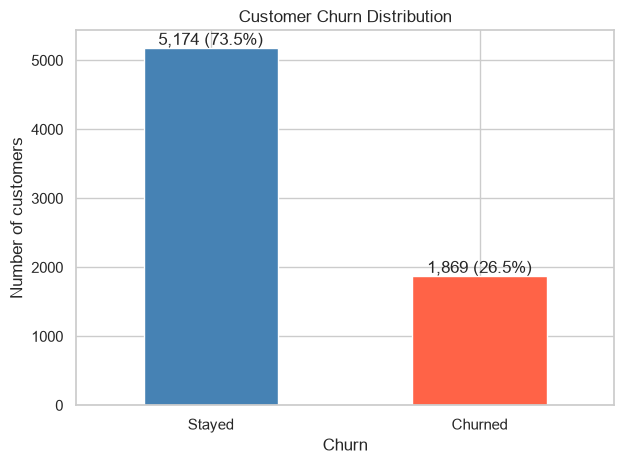

In [3]:
counts = df['Churn'].value_counts().rename({0: 'Stayed', 1: 'Churned'})
ax = counts.plot(kind='bar', color=['steelblue', 'tomato'])
ax.set_title("Customer Churn Distribution")
ax.set_ylabel("Number of customers")
plt.xticks(rotation=0)
for i, v in enumerate(counts):
    ax.text(i, v + 50, f"{v:,} ({v/len(df):.1%})", ha='center')
save_show("01_churn_distribution")

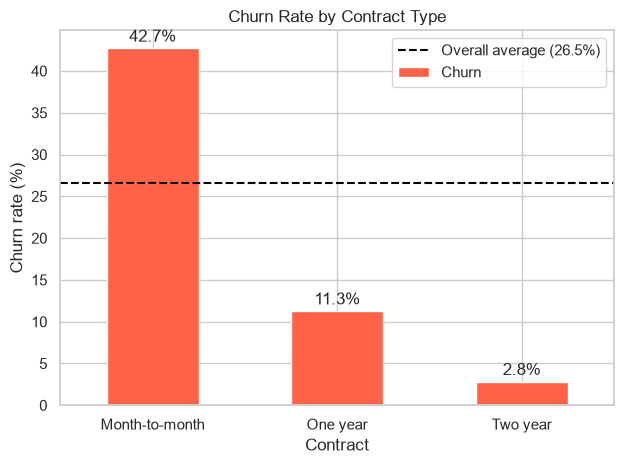

In [4]:
rate = df.groupby('Contract')['Churn'].mean().sort_values(ascending=False) * 100
ax = rate.plot(kind='bar', color='tomato')
ax.set_title("Churn Rate by Contract Type")
ax.set_ylabel("Churn rate (%)")
plt.xticks(rotation=0)
ax.axhline(df['Churn'].mean() * 100, color='black', linestyle='--', label='Overall average (26.5%)')
for i, v in enumerate(rate):
    ax.text(i, v + 0.8, f"{v:.1f}%", ha='center')
ax.legend()
save_show("02_churn_by_contract")

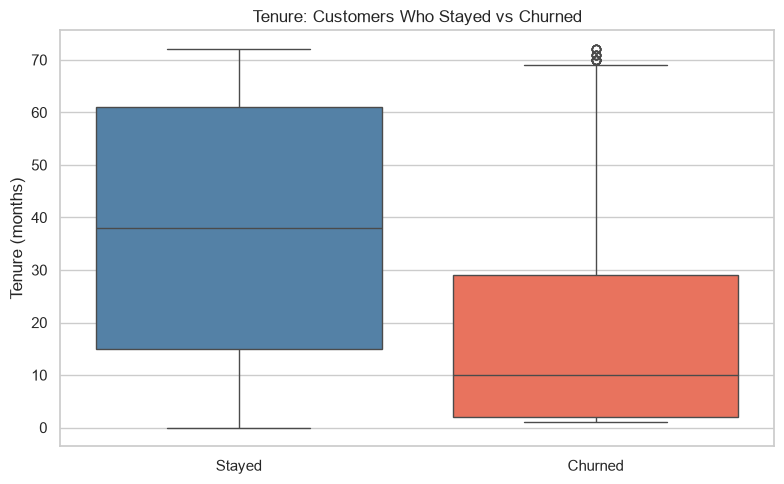

In [5]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['Churn'].map({0: 'Stayed', 1: 'Churned'}), y=df['tenure'],
            palette=['steelblue', 'tomato'], hue=df['Churn'].map({0: 'Stayed', 1: 'Churned'}), legend=False)
plt.title("Tenure: Customers Who Stayed vs Churned")
plt.xlabel("")
plt.ylabel("Tenure (months)")
save_show("03a_tenure_boxplot")

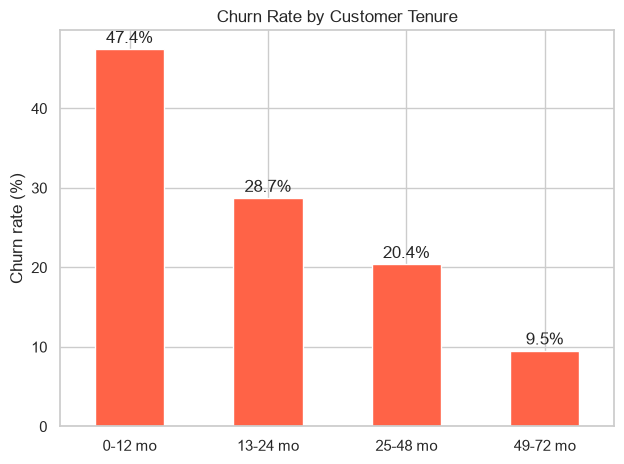

In [6]:
df['tenure_group'] = pd.cut(df['tenure'], bins=[-1, 12, 24, 48, 72],
                            labels=['0-12 mo', '13-24 mo', '25-48 mo', '49-72 mo'])
rate = df.groupby('tenure_group', observed=True)['Churn'].mean() * 100
ax = rate.plot(kind='bar', color='tomato')
ax.set_title("Churn Rate by Customer Tenure")
ax.set_ylabel("Churn rate (%)")
ax.set_xlabel("")
plt.xticks(rotation=0)
for i, v in enumerate(rate):
    ax.text(i, v + 0.8, f"{v:.1f}%", ha='center')
save_show("03b_churn_by_tenure_group")

In [7]:
# only needed if you save df again later
# df = df.drop(columns='tenure_group')

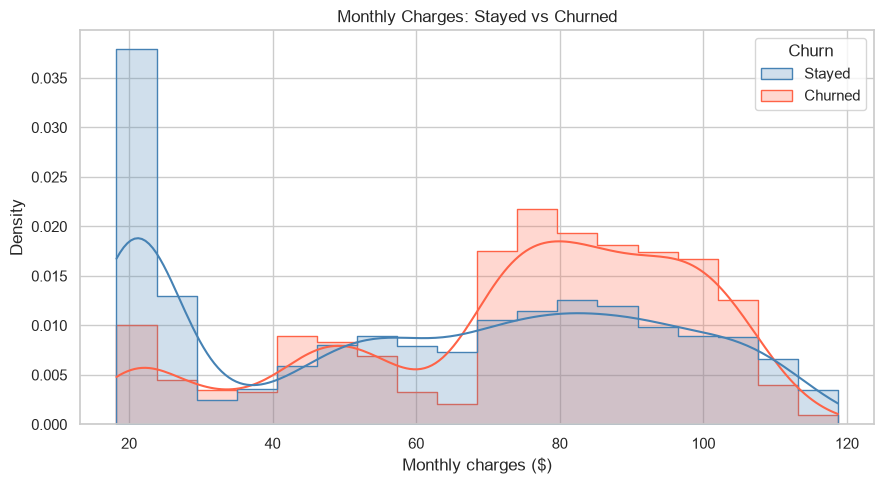

Churn
0    61.27
1    74.44
Name: MonthlyCharges, dtype: float64


In [8]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='MonthlyCharges', hue=df['Churn'].map({0: 'Stayed', 1: 'Churned'}),
             kde=True, element='step', stat='density', common_norm=False,
             palette=['steelblue', 'tomato'])
plt.title("Monthly Charges: Stayed vs Churned")
plt.xlabel("Monthly charges ($)")
save_show("04_monthly_charges")

print(df.groupby('Churn')['MonthlyCharges'].mean().round(2))

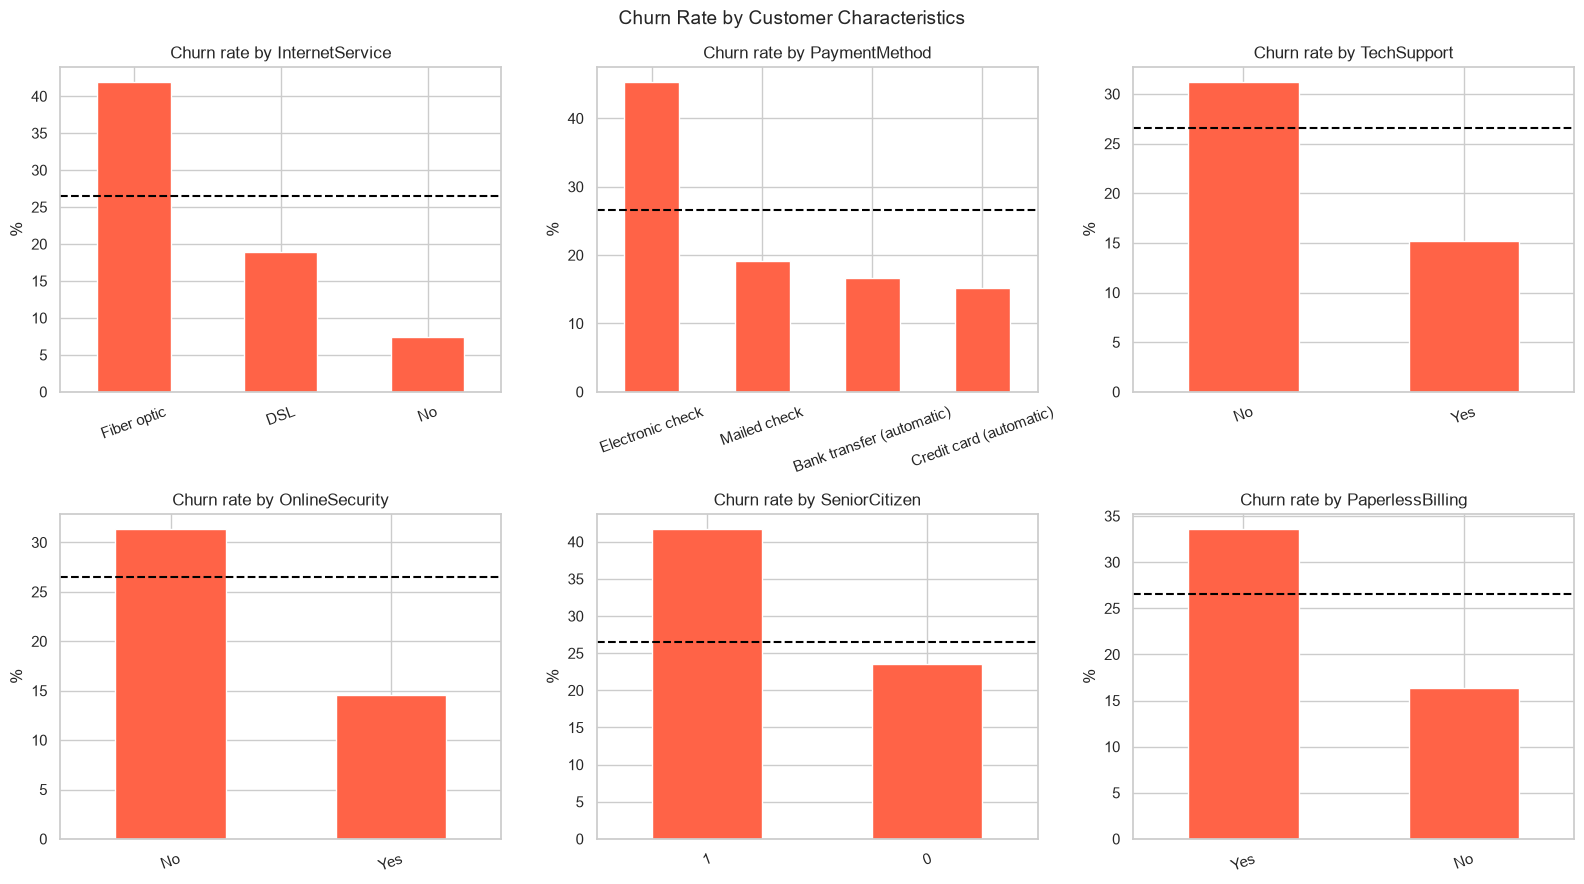

In [9]:
cols = ['InternetService', 'PaymentMethod', 'TechSupport', 'OnlineSecurity',
        'SeniorCitizen', 'PaperlessBilling']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, cols):
    rate = df.groupby(col)['Churn'].mean().sort_values(ascending=False) * 100
    rate.plot(kind='bar', ax=ax, color='tomato')
    ax.axhline(df['Churn'].mean() * 100, color='black', linestyle='--')
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("%")
    ax.set_xlabel("")
    ax.tick_params(axis='x', rotation=20)
plt.suptitle("Churn Rate by Customer Characteristics", fontsize=14)
save_show("05_churn_by_category")

In [10]:
print((df.groupby('gender')['Churn'].mean() * 100).round(1))

gender
Female    26.9
Male      26.2
Name: Churn, dtype: float64


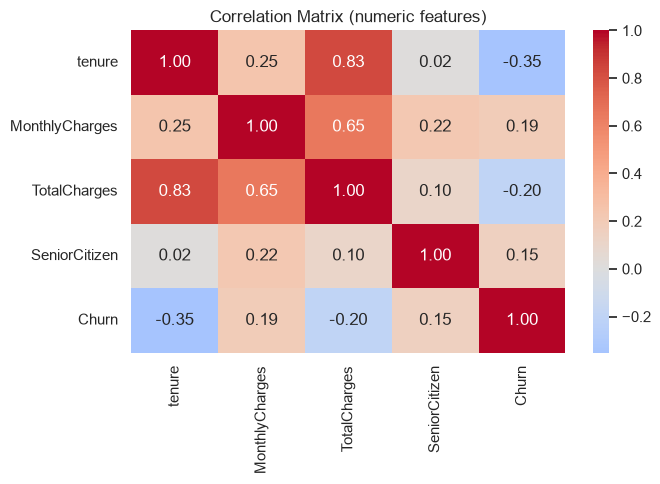

In [11]:
num = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'Churn']]
plt.figure(figsize=(7, 5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix (numeric features)")
save_show("06_correlation_heatmap")

## Key Insights

1. **Overall churn is 26.5%** (1,869 of 7,043 customers), so the data is imbalanced.
2. **Contract type is the strongest driver.** Month-to-month customers churn at ~43% vs ~3% for two-year contracts.
3. **New customers are the most at risk.** Churn is highest in the first 12 months and falls with tenure.
4. **Fiber optic customers churn more (~42%)** than DSL (~19%), possibly due to higher prices or service quality. This needs further investigation.
5. **Electronic check payers churn at ~45%**, roughly 3x other payment methods.
6. **Customers with Tech Support or Online Security churn about half as often** as those without.
7. **Gender has almost no effect** on churn.

## Business Recommendations
- Offer incentives for month-to-month customers to switch to 1-2 year contracts.
- Run onboarding and retention campaigns in the first 12 months.
- Bundle or promote Tech Support and Online Security, especially for fiber customers.
- Investigate fiber optic service quality and pricing.
- Encourage automatic payment methods over electronic check.

## Caveat
These patterns show association, not proven causation. Features overlap (for example, fiber customers pay more and are more often on month-to-month plans), so the model on Day 5-6 will help separate their effects.